<a href="https://colab.research.google.com/github/AMAO-06/AI-ML/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1: Creating a Messy Dataset & Feature Engineering

To prepare for our SVM model, we will first construct a messy synthetic dataset. This dataset will include:
- **Numerical Features** (e.g., Study Hours, Attendance) on different scales.
- **Categorical Features** (e.g., Student Type, School Support) requiring different types of encoding.
- **Missing Values** to practice basic imputation.

Let's generate the dataset and observe its structure.

In [ ]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)
num_students = 250

# Generate features
study_hours = np.random.uniform(1.0, 20.0, num_students)
attendance = np.random.uniform(50.0, 100.0, num_students)
student_type = np.random.choice(['Local', 'International', 'Transfer'], size=num_students)
school_support = np.random.choice(['Yes', 'No'], size=num_students, p=[0.3, 0.7])

# Create some messy missing values
study_hours[np.random.choice(num_students, size=15, replace=False)] = np.nan
attendance[np.random.choice(num_students, size=10, replace=False)] = np.nan

# Generate target 'Passed' based on a non-linear relationship + noise
noise = np.random.normal(0, 1.5, num_students)
score = (0.5 * study_hours) + (0.1 * attendance) + (1.5 * (school_support == 'Yes')) + noise - 12
passed = (score > 0).astype(int)

# Compile into a DataFrame
df_messy = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance_Rate': attendance,
    'Student_Type': student_type,
    'School_Support': school_support,
    'Passed': passed
})

display(df_messy.head())
df_messy.info()

,Study_Hours,Attendance_Rate,Student_Type,School_Support,Passed
0,8.116262,64.722445,International,No,0
1,19.063572,69.254886,Transfer,No,1
2,14.907885,92.556834,Local,No,1
3,12.374511,65.846100,Local,No,1
4,3.964354,58.474637,Local,No,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Study_Hours      235 non-null    float64
 1   Attendance_Rate  240 non-null    float64
 2   Student_Type     250 non-null    object 
 3   School_Support   250 non-null    object 
 4   Passed           250 non-null    int64  
dtypes: float64(2), int64(1), object(2)
memory usage: 9.9+ KB


Now, let's process the missing data and apply proper preprocessing:
1. **Imputation**: Fill missing numerical values with their median.
2. **One-Hot Encoding**: For nominal variables like `Student_Type`.
3. **Label Encoding**: For binary categorical variables like `School_Support`.

In [ ]:
# 1. Imputation
df_cleaned = df_messy.copy()
df_cleaned['Study_Hours'] = df_cleaned['Study_Hours'].fillna(df_cleaned['Study_Hours'].median())
df_cleaned['Attendance_Rate'] = df_cleaned['Attendance_Rate'].fillna(df_cleaned['Attendance_Rate'].median())

# 2. Binary Encoding for School_Support (Yes/No -> 1/0)
df_cleaned['School_Support'] = df_cleaned['School_Support'].map({'Yes': 1, 'No': 0})

# 3. One-Hot Encoding for Student_Type
df_cleaned = pd.get_dummies(df_cleaned, columns=['Student_Type'], drop_first=True)

display(df_cleaned.head())

,Study_Hours,Attendance_Rate,School_Support,Passed,Student_Type_Local,Student_Type_Transfer
0,8.116262,64.722445,0,0,False,False
1,19.063572,69.254886,0,1,False,True
2,14.907885,92.556834,0,1,True,False
3,12.374511,65.846100,0,1,True,False
4,3.964354,58.474637,0,0,True,False


# Stage 2: Train-Test Split & Feature Scaling

Before feeding our features into a Support Vector Machine, we need to perform two vital steps:
1. **Train-Test Split**: Divide our dataset into a training set (to fit our model) and a testing set (to evaluate how well our model generalizes to unseen data).
2. **Feature Scaling (Standardization)**: SVM algorithms find a decision boundary by maximizing the margin between classes using geometric distance. Features with larger numeric ranges will dominate the distance calculations. Therefore, scaling features to have a mean of 0 and standard deviation of 1 is required.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate our features (X) and our target label (y)
X = df_cleaned.drop(columns=['Passed'])
y = df_cleaned['Passed']

# Step 1: Split the dataset into 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Step 2: Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify the scaling by viewing the mean and standard deviation of scaled features
print("Scaling verification:")
print("Mean of scaled training features:", np.round(X_train_scaled.mean(axis=0), 2))
print("Standard Deviation of scaled training features:", np.round(X_train_scaled.std(axis=0), 2))
print(f"\nTrain set size: {X_train_scaled.shape[0]} samples")
print(f"Test set size: {X_test_scaled.shape[0]} samples")

Scaling verification:
Mean of scaled training features: [-0.  0. -0. -0.  0.]
Standard Deviation of scaled training features: [1. 1. 1. 1. 1.]

Train set size: 200 samples
Test set size: 50 samples


# Stage 3: Training a Linear SVM Model

Now that our dataset has been preprocessed, encoded, split, and scaled, we are ready to build our first Support Vector Machine classifier!

We will start with a **Linear Support Vector Classifier (SVC)**. A linear SVM finds a straight line (or hyperplane in higher dimensions) that separates our classes (Passed vs. Failed) with the maximum margin.

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Initialize the Linear Support Vector Classifier
# C is the regularization parameter. A larger C tries to minimize training errors (hard margin).
linear_svm = SVC(kernel='linear', C=1.0, random_state=42)

# Train (fit) the model on the scaled training features
linear_svm.fit(X_train_scaled, y_train)

# Make predictions on the scaled testing features
y_pred_linear = linear_svm.predict(X_test_scaled)

# Calculate accuracy
linear_accuracy = accuracy_score(y_test, y_pred_linear)
print(f"Linear SVM Test Accuracy: {linear_accuracy * 100:.2f}%")

Linear SVM Test Accuracy: 74.00%


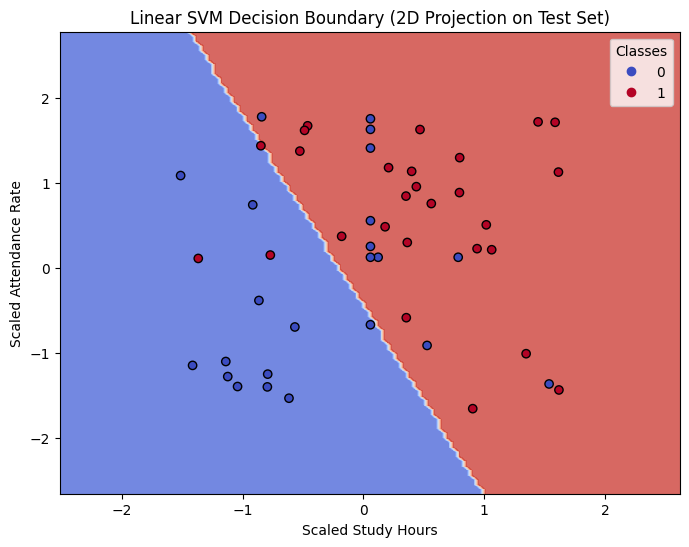

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

# Extract only the first two continuous features (Study_Hours and Attendance_Rate)
X_train_2d = X_train_scaled[:, :2]
X_test_2d = X_test_scaled[:, :2]

# Train a helper 2D linear SVM model for visualization
linear_svm_2d = SVC(kernel='linear', C=1.0, random_state=42)
linear_svm_2d.fit(X_train_2d, y_train)

fig, ax = plt.subplots(figsize=(8, 6))

# Plot the decision boundary
DecisionBoundaryDisplay.from_estimator(
    linear_svm_2d,
    X_test_2d,
    ax=ax,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    xlabel="Scaled Study Hours",
    ylabel="Scaled Attendance Rate"
)

# Plot the test points
scatter = ax.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test,
    edgecolors='k',
    cmap=plt.cm.coolwarm
)

ax.legend(*scatter.legend_elements(), title="Classes")
plt.title("Linear SVM Decision Boundary (2D Projection on Test Set)")
plt.show()

# Stage 4: Non-Linear Boundaries & The Kernel Trick

Sometimes, student behaviors or real-world parameters do not follow a simple linear relationship. In this stage, we will explore the **Kernel Trick**.

Instead of searching for a linear line in the original feature space, SVM uses mathematical functions called **kernels** to project data into a higher-dimensional space where a linear boundary can separate the classes. When projected back down, this boundary looks curved or non-linear!

We will fit an SVM model with:
- **RBF (Radial Basis Function) Kernel**: Great for complex, spherical clusters of data.
- **Polynomial Kernel**: Fits polynomial decision boundaries.

In [ ]:
# Train an RBF Kernel Support Vector Machine
rbf_svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
rbf_svm.fit(X_train_scaled, y_train)

# Train a Polynomial Kernel Support Vector Machine
poly_svm = SVC(kernel='poly', degree=3, C=1.0, random_state=42)
poly_svm.fit(X_train_scaled, y_train)

# Evaluate and compare accuracies
y_pred_rbf = rbf_svm.predict(X_test_scaled)
y_pred_poly = poly_svm.predict(X_test_scaled)

print(f"RBF Kernel SVM Test Accuracy: {accuracy_score(y_test, y_pred_rbf) * 100:.2f}%")
print(f"Polynomial Kernel SVM Test Accuracy: {accuracy_score(y_test, y_pred_poly) * 100:.2f}%")

RBF Kernel SVM Test Accuracy: 68.00%
Polynomial Kernel SVM Test Accuracy: 72.00%


# Stage 5: Hyperparameter Tuning with Grid Search

In the previous steps, we picked arbitrary values for our hyperparameters (like `C=1.0` or `kernel='rbf'`). To build the absolute best model, we should systematically try multiple combinations of:
1. **$C$**: The penalty for misclassifying training points.
2. **$\gamma$ (Gamma)**: The influence range of a single training point (for non-linear kernels).
3. **Kernel**: Linear, RBF, or Polynomial.

We will use `GridSearchCV` from Scikit-Learn, which automatically trains models across combinations using cross-validation to ensure our parameters generalize well to unseen data.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid search options
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf', 'poly']
}

# Initialize GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# Fit on the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Display results
print("Optimal Hyperparameters found:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

Optimal Hyperparameters found:
{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Best Cross-Validation Accuracy: 87.50%


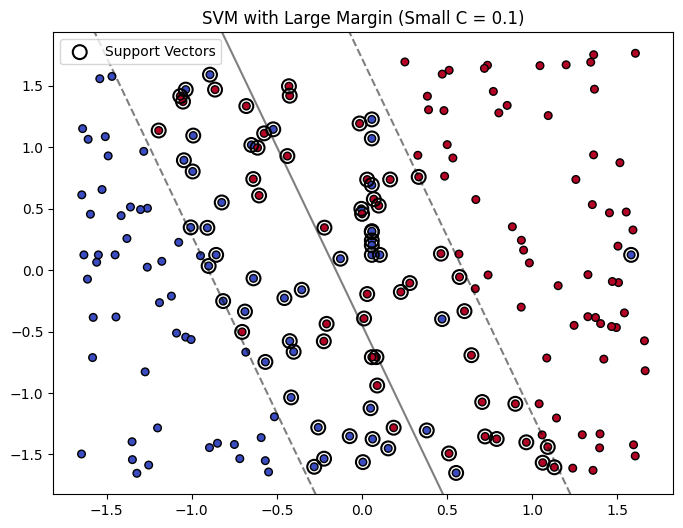

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC

# 1. Define and train the missing 'model' variable on the 2D scaled data
# We use C=0.1 as specified in the plot title
model = SVC(kernel='linear', C=0.1, random_state=42)
model.fit(X_2d, y_train)

# 2. Setup the plot on the 2D scaled feature space
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, s=30, cmap=plt.cm.coolwarm, edgecolors='k')

xlim = ax.get_xlim()
ylim = ax.get_ylim()

# 3. Create a grid to plot the decision boundary and margins
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = model.decision_function(xy).reshape(XX.shape)

# 4. Plot decision boundary and margins
ax.contour(
    XX,
    YY,
    Z,
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"]
)

# 5. Highlight the support vectors
ax.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=100,
    linewidth=1.5,
    facecolors="none",
    edgecolors="k",
    label="Support Vectors"
)

plt.title("SVM with Large Margin (Small C = 0.1)")
plt.legend()
plt.show()

# Stage 6: Final Evaluation & Communication

Once we have selected our best estimator from Grid Search, we must perform a final rigorous evaluation on the test set (the data the model has never seen during training or tuning).

We will evaluate the model using:
1. **Classification Report**: Displaying precision, recall, and F1-score.
2. **Confusion Matrix**: Visualizing true positives, true negatives, false positives, and false negatives.

Evaluating the optimal model selected by Grid Search:
{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}

Final Evaluation Report:

              precision    recall  f1-score   support

           0       0.80      0.52      0.63        23
           1       0.69      0.89      0.77        27

    accuracy                           0.72        50
   macro avg       0.74      0.71      0.70        50
weighted avg       0.74      0.72      0.71        50



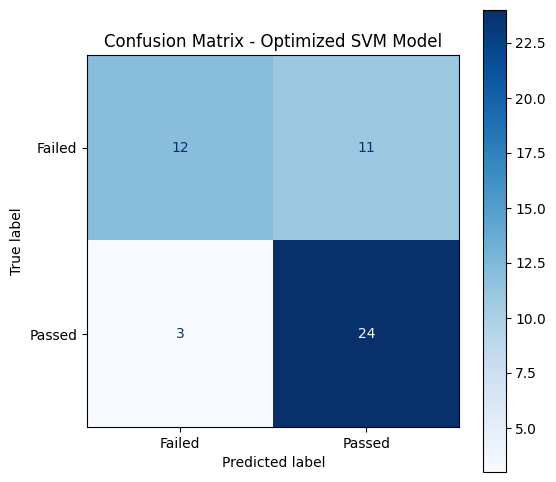

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# We extract the optimal model selected by Grid Search
best_model = grid_search.best_estimator_
print("Evaluating the optimal model selected by Grid Search:")
print(grid_search.best_params_)

# Make predictions on the scaled test set
y_pred_final = best_model.predict(X_test_scaled)

# 1. Print detailed classification report
print("\nFinal Evaluation Report:\n")
print(classification_report(y_test, y_pred_final))

# 2. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Failed', 'Passed'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title("Confusion Matrix - Optimized SVM Model")
plt.show()

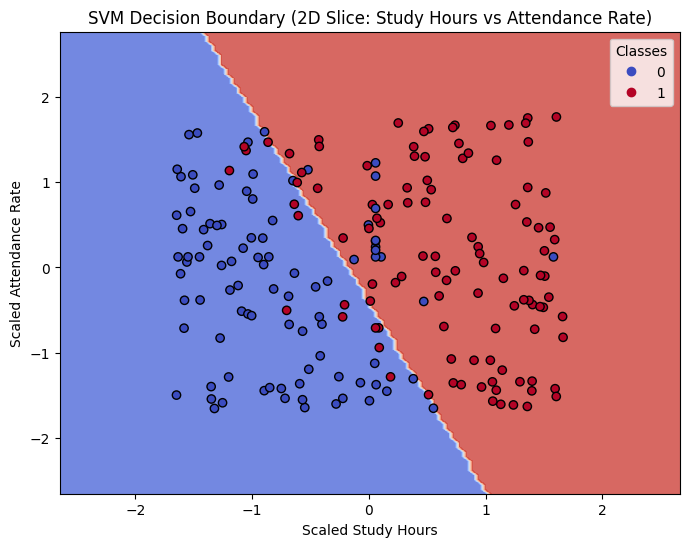

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
import numpy as np
from sklearn import svm

# We will use the two primary continuous features (Study_Hours and Attendance_Rate) for boundary visualization
# We need a 2D feature space to plot a 2D decision boundary.
# Let's retrain a 2D SVM on just those two scaled features for demonstration
X_2d = X_train_scaled[:, :2]
svm_2d = SVC(kernel='linear', C=10, random_state=42).fit(X_2d, y_train)

fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_2d,
    X_2d,
    ax=ax,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    xlabel="Scaled Study Hours",
    ylabel="Scaled Attendance Rate"
)

# Plot the actual training points on top
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.coolwarm)
ax.legend(*scatter.legend_elements(), title="Classes")
plt.title("SVM Decision Boundary (2D Slice: Study Hours vs Attendance Rate)")
plt.show()